In [1]:
import sys
sys.path.append('../src')
from preprocessing import load_and_preprocess, split_and_scale

# Load data and prepare for regression
X, y_reg, _ = load_and_preprocess()
X_train, X_test, y_train, y_test = split_and_scale(X, y_reg)

print(f"Training data shape: {X_train.shape}")

Training data shape: (13903, 11)


--- Linear Regression (Baseline) ---
RMSE: 139.44 | MAE: 104.98 | R²: 0.3860

--- Random Forest (Ensemble) ---
RMSE: 42.30 | MAE: 24.80 | R²: 0.9435



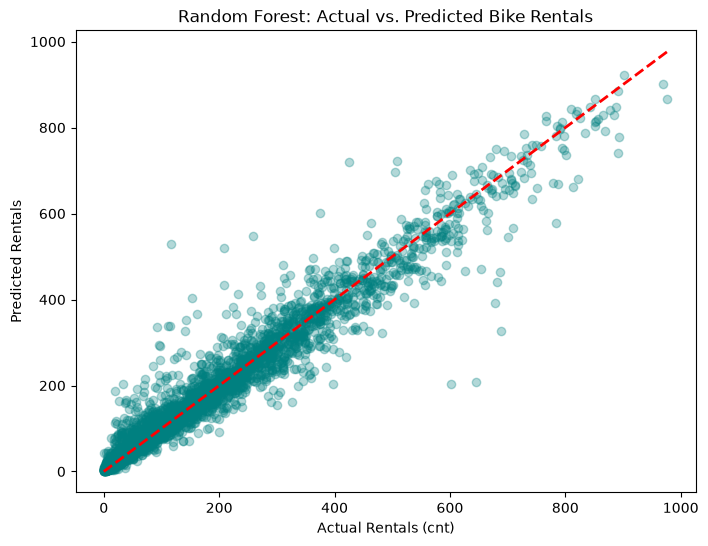

In [2]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Train a baseline linear model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

# 2. Train a complex ensemble model (Random Forest)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

# 3. Evaluation function
def evaluate_model(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"RMSE: {rmse:.2f} | MAE: {mae:.2f} | R²: {r2:.4f}\n")

# Evaluate both models
evaluate_model("Linear Regression (Baseline)", y_test, lr_preds)
evaluate_model("Random Forest (Ensemble)", y_test, rf_preds)

# 4. Visualizing True vs Predicted for Random Forest
plt.figure(figsize=(8, 6))
plt.scatter(y_test, rf_preds, alpha=0.3, color='teal')
plt.plot([0, y_test.max()], [0, y_test.max()], '--', color='red', linewidth=2) # Perfect prediction line
plt.title("Random Forest: Actual vs. Predicted Bike Rentals")
plt.xlabel("Actual Rentals (cnt)")
plt.ylabel("Predicted Rentals")
plt.savefig('../figures/rf_regression_results.png') # Save for the MLLB LaTeX report
plt.show()

In [3]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "max_depth": [None, 10, 20, 30, 40],
    "n_estimators": [100, 200, 300, 500],
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=1),
    param_distributions=param_distributions,
    n_iter=10,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

rf_search.fit(X_train, y_train)

best_rf_model = rf_search.best_estimator_
best_rf_model.n_jobs = -1
best_rf_preds = best_rf_model.predict(X_test)

print("Best parameters:", rf_search.best_params_)
print(f"Best CV RMSE: {-rf_search.best_score_:.2f}")
evaluate_model("Tuned Random Forest", y_test, best_rf_preds)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'n_estimators': 500, 'max_depth': 30}
Best CV RMSE: 45.28
--- Tuned Random Forest ---
RMSE: 42.03 | MAE: 24.67 | R²: 0.9442

